***
<center>IMPORTS</center>


In [35]:
from statsmodels.tsa.stattools import adfuller
import pandas as pd
import matplotlib.pyplot as plt

In [10]:
file = pd.read_csv('data.csv', index_col='date', parse_dates=True)

***
#### Тест Дики–Фуллера (ADF) для уровней рядов

**Гипотезы:**
- H₀: ряд нестационарен (есть единичный корень);
- H₁: ряд стационарен.

Уровень значимости — 5%

In [19]:
result_infl = adfuller(file['infl'])

result_key_rate = adfuller(file['key_rate'])

In [23]:
print(f'ADF Statistic for infl: {round(result_infl[0], 2)}')
print(f'p-value for infl: {round(result_infl[1],2)}')

print(f'ADF Statistic for key_rate: {round(result_key_rate[0], 2)}')
print(f'p-value for key_rate: {round(result_key_rate[1],2)}')

ADF Statistic for infl: -2.2
p-value for infl: 0.21
ADF Statistic for key_rate: -2.36
p-value for key_rate: 0.15


***
**Вывод:** 
для обоих рядов p-value > 0.05,
поэтому H₀ не отвергается — ряды нестационарны. 

Строить ARIMA и VAR на уровнях нельзя — возможна ложная регрессия

***
Проверим стационарность первых разностей

In [28]:
d_infl = file['infl'].diff().dropna()

d_key_rate = file['key_rate'].diff().dropna()

***
Тест Дики–Фуллера (ADF) для первых разностей

**Гипотезы:**
- H₀: ряд нестационарен;
- H₁: ряд стационарен.

Уровень значимости — 5%

In [29]:
test_1diff_infl = adfuller(d_infl)

test_1diff_key_rate = adfuller(d_key_rate)

In [34]:
print(f'ADF Statistic for diff1 infl : {round(test_1diff_infl[0], 5)}')
print(f'p-value for diff1 infl: {round(test_1diff_infl[1],5)}')

print(f'ADF Statistic for diff1 key_rate: {round(test_1diff_key_rate[0], 5)}')
print(f'p-value for diff1 key_rate: {round(test_1diff_key_rate[1], 5)}') 

ADF Statistic for diff1 infl : -4.03142
p-value for diff1 infl: 0.00125
ADF Statistic for diff1 key_rate: -8.20119
p-value for diff1 key_rate: 0.0


| Ряд | ADF-статистика | p-value | Вывод |
|---|---|---|---|
| Инфляция, г/г | −2.20 | 0.21 | нестационарен |
| Ключевая ставка | −2.36 | 0.15 | нестационарен |
| Δ Инфляция (разность) | −4.03 | 0.001 | **стационарен** |
| Δ Ключевая ставка (разность) | −8.20 | < 0.001 | **стационарен** |

Первые разности (изменения за месяц) стационарны: H₀ отвергается (p < 0.05).
Значит, оба ряда **интегрированы первого порядка — I(1)**.

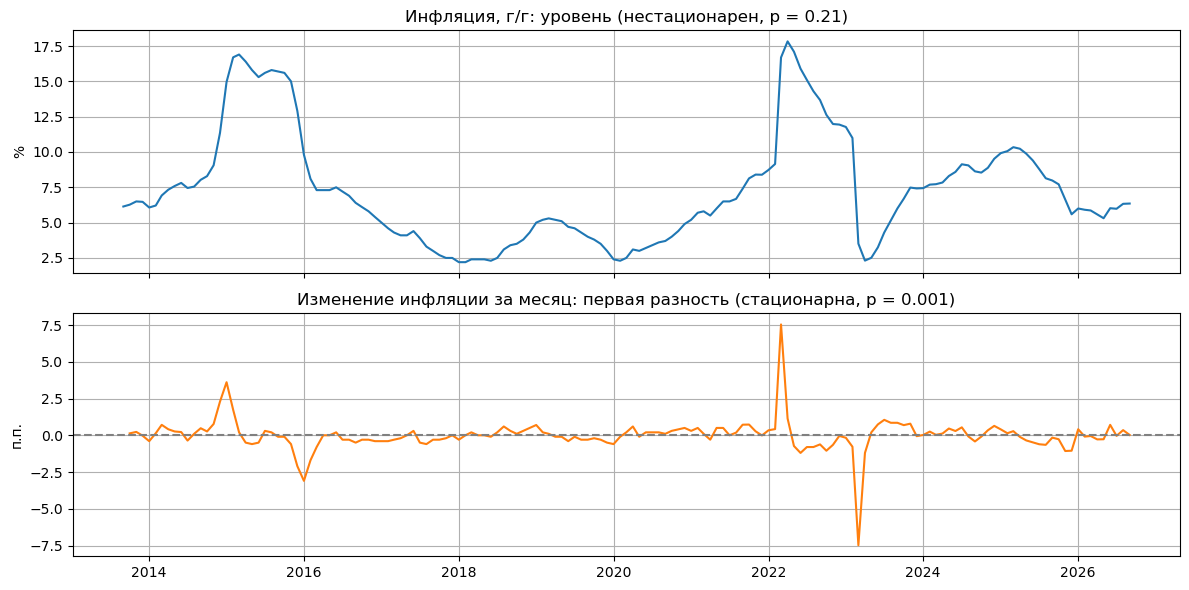

In [36]:
fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)

axes[0].plot(file['infl'])
axes[0].set_title('Инфляция, г/г: уровень (нестационарен, p = 0.21)')
axes[0].set_ylabel('%')
axes[0].grid()

axes[1].plot(d_infl, color='tab:orange')
axes[1].axhline(0, color='gray', linestyle='--')
axes[1].set_title('Изменение инфляции за месяц: первая разность (стационарна, p = 0.001)')
axes[1].set_ylabel('п.п.')
axes[1].grid()

plt.tight_layout()
plt.show()